# A simple 2D Discrete Flow Matching model, Shaul et al
* uniform noise patterns

# co-authors for this colab example: Denisa Roberts and Gemini

# reference codes and paper
https://github.com/facebookresearch/flow_matching/blob/main/examples/2d_discrete_flow_matching.ipynb

Flow Matching with General Discrete Paths: A Kinetic-Optimal Perspective

https://arxiv.org/abs/2412.03487


This notebook trains and evaluates a simple 2D discrete FM model with $\kappa_t = t^2$ scheduler.

Dataset: 2D discrete checkerboard
Model (probability denoiser): MLP

In [ ]:
!git clone https://github.com/facebookresearch/flow_matching.git

Cloning into 'flow_matching'...
remote: Enumerating objects: 2020, done.
remote: Counting objects: 100% (1186/1186), done.
remote: Compressing objects: 100% (306/306), done.
remote: Total 2020 (delta 1086), reused 880 (delta 880), pack-reused 834 (from 2)
Receiving objects: 100% (2020/2020), 9.38 MiB | 27.52 MiB/s, done.
Resolving deltas: 100% (1627/1627), done.


In [ ]:
%cd flow_matching

# 3. Install the package and its requirements
!pip install -e .

/content/flow_matching
Obtaining file:///content/flow_matching
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for flow_matching (pyproject.toml) ... done
  Created wheel for flow_matching: filename=flow_matching-1.0.10-0.editable-py3-none-any.whl size=11054 sha256=ae5a4c8b2bd8c9da07186a2bec748342e161d49448df5d73b20eb233e798eb63
  Stored in directory: /tmp/pip-ephem-wheel-cache-b8prg6jg/wheels/c2/1a/e7/ba16571a163a78e21a25399434845f66633a9f8d3638883791
Successfully built flow_matching
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [flow_matching]


## Imports and init device

In [ ]:
import time
import torch

from torch import nn, Tensor

# flow_matching
from flow_matching.path import MixtureDiscreteProbPath
from flow_matching.path.scheduler import PolynomialConvexScheduler
from flow_matching.solver import MixtureDiscreteEulerSolver
from flow_matching.utils import ModelWrapper
from flow_matching.loss import MixturePathGeneralizedKL

# visualization
import numpy as np
import matplotlib.cm as cm
import matplotlib.pyplot as plt

In [ ]:
if torch.cuda.is_available():
    device = 'cuda:0'
    print('Using gpu')
else:
    device = 'cpu'
    print('Using cpu.')

Using gpu


In [ ]:
torch.manual_seed(42)

## Dataset

In [ ]:
def inf_train_gen(n_grid_points: int = 128, batch_size: int = 200, device: str = "cpu") -> Tensor:
    assert n_grid_points % 4 == 0, "number of grid points has to be divisible by 4"

    n_grid_points = n_grid_points // 4

    x1 = torch.randint(low=0, high=n_grid_points * 4, size=(batch_size,), device=device)
    samples_x2 = torch.randint(low=0, high=n_grid_points, size=(batch_size,), device=device)

    x2 = (
        samples_x2
        + 2 * n_grid_points
        - torch.randint(low=0, high=2, size=(batch_size,), device=device) * 2 * n_grid_points
        + (torch.floor(x1 / n_grid_points) % 2) * n_grid_points
    )

    x_end = 1.0 * torch.cat([x1[:, None], x2[:, None]], dim=1)

    return x_end.long()

## Model

In [ ]:
# Activation class
class Swish(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x: Tensor) -> Tensor:
        return torch.sigmoid(x) * x

# Model class
class MLP(nn.Module):
    def __init__(
        self, input_dim: int = 128, time_dim: int = 1, hidden_dim=128, length=2):
        super().__init__()
        self.input_dim = input_dim
        self.time_dim = time_dim
        self.hidden_dim = hidden_dim

        self.time_embedding = nn.Linear(1, time_dim)
        self.token_embedding = torch.nn.Embedding(self.input_dim, hidden_dim)

        self.main = nn.Sequential(
            Swish(),
            nn.Linear(hidden_dim * length + time_dim, hidden_dim),
            Swish(),
            nn.Linear(hidden_dim, hidden_dim),
            Swish(),
            nn.Linear(hidden_dim, hidden_dim),
            Swish(),
            nn.Linear(hidden_dim, self.input_dim * length),
        )

    def forward(self, x, t):
        t = self.time_embedding(t.unsqueeze(-1))
        x = self.token_embedding(x)

        B, N, d = x.shape
        x = x.reshape(B, N * d)

        h = torch.cat([x, t], dim=1)
        h = self.main(h)

        h = h.reshape(B, N, self.input_dim)

        return h

## Train Discrete Flow Matching model with a uniform source distribution

In [ ]:
source_distribution = "uniform"

# training arguments
lr = 0.001
batch_size = 4096
iterations = 30001
print_every = 3000

vocab_size = 128
hidden_dim = 128

epsilon = 1e-3

if source_distribution == "uniform":
    added_token = 0
elif source_distribution == "mask":
    mask_token = vocab_size  # tokens starting from zero
    added_token = 1
else:
    raise NotImplementedError

# additional mask token
vocab_size += added_token

# probability denoiser model init
probability_denoiser = MLP(input_dim=vocab_size, time_dim=1, hidden_dim=hidden_dim).to(device)

# instantiate a convex path object
scheduler = PolynomialConvexScheduler(n=2.0)
path = MixtureDiscreteProbPath(scheduler=scheduler)

# init optimizer
optim = torch.optim.Adam(probability_denoiser.parameters(), lr=lr)

loss_fn = MixturePathGeneralizedKL(path=path)

# train
start_time = time.time()

steps = 0
losses = []
for i in range(iterations):
    optim.zero_grad()

    # sample data (user's responsibility): in this case, (X_0,X_1) ~ pi(X_0,X_1)
    x_1 = inf_train_gen(n_grid_points=vocab_size - added_token, batch_size=batch_size, device=device) # sample data

    if source_distribution == "uniform":
        x_0 = torch.randint_like(x_1, high=vocab_size)
    elif source_distribution == "mask":
        x_0 = torch.zeros_like(x_1) + mask_token
    else:
        raise NotImplementedError

    # sample time (user's responsibility)
    t = torch.rand(x_1.shape[0]).to(device) * (1 - epsilon)

    # sample probability path
    path_sample = path.sample(t=t, x_0=x_0, x_1=x_1)

    # discrete flow matching generalized KL loss
    logits = probability_denoiser(x=path_sample.x_t, t=path_sample.t)
    loss = loss_fn(logits=logits, x_1=x_1, x_t=path_sample.x_t, t=path_sample.t)

    # optimizer step
    loss.backward() # backward
    optim.step() # update

    # log loss
    if (i+1) % print_every == 0:
        elapsed = time.time() - start_time
        print('| iter {:6d} | {:5.2f} ms/step | loss {:8.3f} '
              .format(i+1, elapsed*1000/print_every, loss.item()))
        start_time = time.time()

| iter   3000 |  4.17 ms/step | loss    5.697 
| iter   6000 |  3.70 ms/step | loss    5.539 
| iter   9000 |  3.66 ms/step | loss    5.296 
| iter  12000 |  3.74 ms/step | loss    5.520 
| iter  15000 |  3.77 ms/step | loss    5.714 
| iter  18000 |  3.69 ms/step | loss    5.556 
| iter  21000 |  3.62 ms/step | loss    5.392 
| iter  24000 |  3.60 ms/step | loss    5.354 
| iter  27000 |  3.68 ms/step | loss    6.423 
| iter  30000 |  3.70 ms/step | loss    5.445 


#### Sample from trained model

In [ ]:
class WrappedModel(ModelWrapper):
    def forward(self, x: torch.Tensor, t: torch.Tensor, **extras):
        return torch.softmax(self.model(x, t, **extras), dim=-1)

wrapped_probability_denoiser = WrappedModel(probability_denoiser)
solver = MixtureDiscreteEulerSolver(model=wrapped_probability_denoiser, path=path, vocabulary_size=vocab_size)

In [ ]:
nfe = 64
step_size = 1 / nfe

safe_sampling = True
n_samples = 1000000
dim = 2

if source_distribution == "uniform":
    x_init = torch.randint(size=(n_samples, dim), high=vocab_size, device=device)
elif source_distribution == "mask":
    x_init = (torch.zeros(size=(n_samples, dim), device=device) + mask_token).long()
else:
    raise NotImplementedError

n_plots = 9
linspace_to_plot = torch.linspace(0,  1 - epsilon, n_plots)

sol = solver.sample(x_init=x_init,
                    step_size=step_size,
                    verbose=True,
                    return_intermediates=True,
                    time_grid=linspace_to_plot)

NFE: 64: 100%|██████████| 0.9990000128746033/0.9990000128746033 [00:17<00:00, 17.74s/it]


In [ ]:
probability_denoiser

MLP(
  (time_embedding): Linear(in_features=1, out_features=1, bias=True)
  (token_embedding): Embedding(128, 128)
  (main): Sequential(
    (0): Swish()
    (1): Linear(in_features=257, out_features=128, bias=True)
    (2): Swish()
    (3): Linear(in_features=128, out_features=128, bias=True)
    (4): Swish()
    (5): Linear(in_features=128, out_features=128, bias=True)
    (6): Swish()
    (7): Linear(in_features=128, out_features=256, bias=True)
  )
)

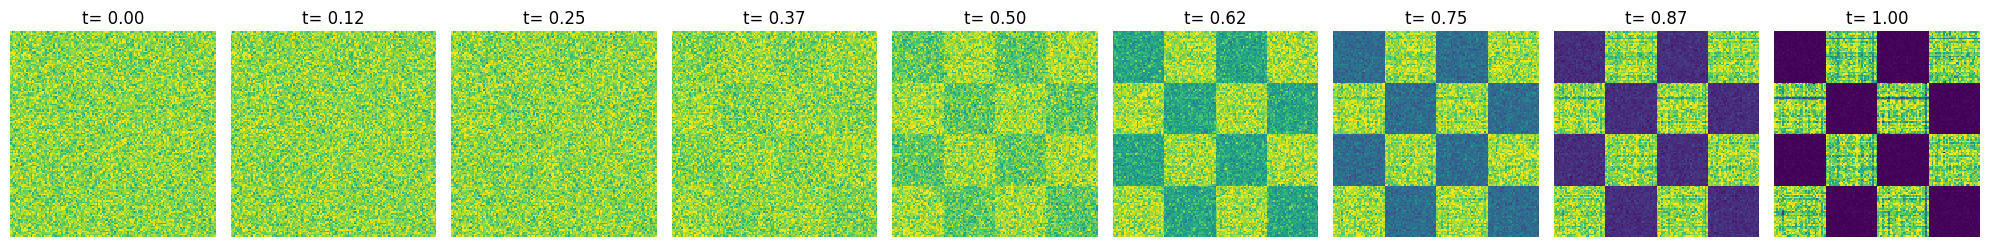

In [ ]:
sol = sol.cpu().numpy()

fig, axs = plt.subplots(1, n_plots, figsize = (20, 20))

for idx, step in enumerate(linspace_to_plot):
    step = int(step.item() * nfe)

    if source_distribution == "uniform":
        sol_step = sol[idx, ...]

    else:
        raise NotImplementedError

    H = axs[idx].hist2d(sol_step[:, 0], sol_step[:, 1], bins=vocab_size)

    cmin = 0.0
    cmax = torch.quantile(torch.from_numpy(H[0]), 0.95).item()

    norm = cm.colors.Normalize(vmax=cmax, vmin=cmin)

    _ = axs[idx].hist2d(sol_step[:, 0], sol_step[:, 1], bins=vocab_size, norm=norm)

    axs[idx].set_aspect('equal')
    axs[idx].axis('off')
    axs[idx].set_title(f't= {linspace_to_plot[idx].item():.2f}')

plt.tight_layout()
plt.show()

NFE: 64: 100%|██████████| 0.9999899864196777/0.9999899864196777 [00:17<00:00, 17.07s/it]


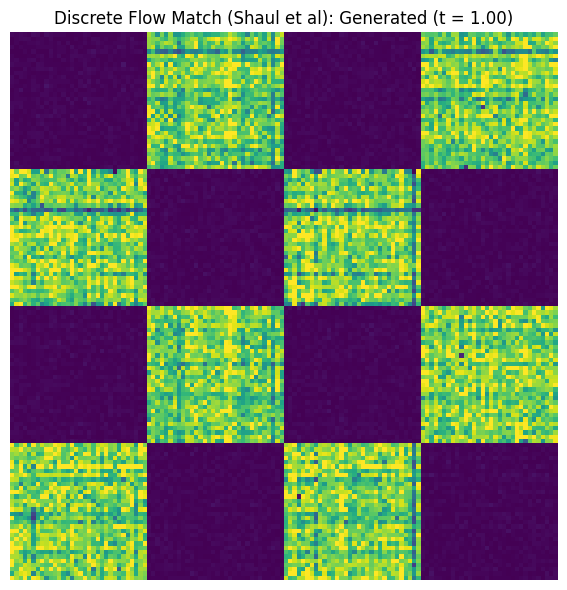

In [ ]:
import torch
import matplotlib.pyplot as plt
from matplotlib import cm

# ---------------------------------------------------------
# 1. Sampling Parameters & Generation
# ---------------------------------------------------------

nfe = 64
step_size = 1 / nfe
safe_sampling = True
n_samples = 1000000  # Set to match ground truth sample count (e.g., 100k or 1M)
dim = 2

# Initial distribution
if source_distribution == "uniform":
    x_init = torch.randint(size=(n_samples, dim), high=vocab_size, device=device)
elif source_distribution == "mask":
    x_init = (torch.zeros(size=(n_samples, dim), device=device) + mask_token).long()
else:
    raise NotImplementedError

# Define sampling time grid
n_plots = 9
linspace_to_plot = torch.linspace(0, 1 - 1e-5, n_plots)

# Run solver sampling
sol = solver.sample(
    x_init=x_init,
    step_size=step_size,
    verbose=True,
    return_intermediates=True,
    time_grid=linspace_to_plot,
)

sol = sol.cpu().numpy()

# Extract final time step (t = 1.0)
final_samples = sol[-1]  # Shape: (n_samples, 2)

# ---------------------------------------------------------
# 2. Final Step Heatmap (Exact Ground Truth Plot Style)
# ---------------------------------------------------------

fig, ax = plt.subplots(1, 1, figsize=(6, 6))

# First pass to compute histogram array H
H = ax.hist2d(final_samples[:, 0], final_samples[:, 1], bins=vocab_size)

cmin = 0.0
cmax = torch.quantile(torch.from_numpy(H[0]), 0.95).item()

norm = cm.colors.Normalize(vmax=cmax, vmin=cmin)

# Clear un-normalized initial pass and re-render with 95th quantile normalization
ax.cla()
_ = ax.hist2d(final_samples[:, 0], final_samples[:, 1], bins=vocab_size, norm=norm)

ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Discrete Flow Match (Shaul et al): Generated (t = 1.00)")

plt.tight_layout()
plt.show()

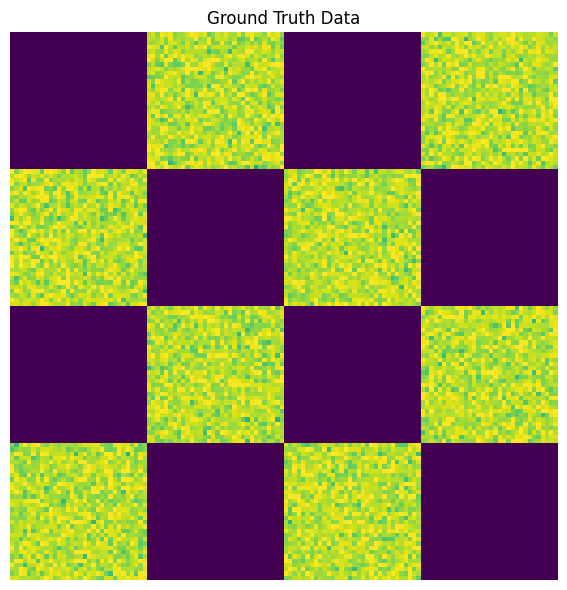

In [ ]:
#ground truth plot
import torch
import matplotlib.pyplot as plt
from matplotlib import cm

# ---------------------------------------------------------
# 1. Ground Truth Checkerboard Data Generator
# ---------------------------------------------------------

def inf_train_gen(n_grid_points: int = 128, batch_size: int = 100000, device: str = "cpu") -> torch.Tensor:
    assert n_grid_points % 4 == 0, "number of grid points has to be divisible by 4"
    sub_grid = n_grid_points // 4

    x1 = torch.randint(low=0, high=sub_grid * 4, size=(batch_size,), device=device)
    samples_x2 = torch.randint(low=0, high=sub_grid, size=(batch_size,), device=device)

    x2 = (
        samples_x2
        + 2 * sub_grid
        - torch.randint(low=0, high=2, size=(batch_size,), device=device) * 2 * sub_grid
        + (torch.floor(x1 / sub_grid) % 2) * sub_grid
    )

    x_end = torch.cat([x1[:, None], x2[:, None]], dim=1)
    return x_end.long()


# ---------------------------------------------------------
# 2. Ground Truth Plotting
# ---------------------------------------------------------

vocab_size = 128
num_samples = 1000000

# Sample from ground truth distribution
sol_step = inf_train_gen(n_grid_points=vocab_size, batch_size=num_samples, device="cpu").numpy()

fig, ax = plt.subplots(1, 1, figsize=(6, 6))

# First pass to compute histogram array H
H = ax.hist2d(sol_step[:, 0], sol_step[:, 1], bins=vocab_size)

cmin = 0.0
cmax = torch.quantile(torch.from_numpy(H[0]), 0.95).item()

norm = cm.colors.Normalize(vmax=cmax, vmin=cmin)

# Clear un-normalized initial pass and re-render with quantile normalization
ax.cla()
_ = ax.hist2d(sol_step[:, 0], sol_step[:, 1], bins=vocab_size, norm=norm)

ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Ground Truth Data")

plt.tight_layout()
plt.show()